# DynSurvX tutorial: explaining CoxSig predictions

This notebook demonstrates the core DynSurvX workflow on **simulated longitudinal survival data**:

1. Generate longitudinal trajectories and right-censored survival outcomes.
2. Train a Cox Signature (CoxSig) survival model.
3. Evaluate dynamic predictions at landmark times.
4. Compute **individual-level, time-resolved Shapley explanations**.
5. Visualize and aggregate feature and temporal importance.

The example uses `prediction_type="survival"` (the repository's mean/expected remaining survival-time prediction). It is intended as a small, readable tutorial rather than a full paper-reproduction experiment.

**No files, figures, model checkpoints, or intermediate results are written to disk by this notebook.** Figures are displayed inline only.

> Run from the repository root, with the project installed in your active Python environment. The simulated data generator and DynSurvX implementation are imported from the repository.

The setup cell defines `PROJECT_ROOT`, `SRC_DIR`, `EXAMPLES_DIR`, `FIGURE_DIR`, and `RESULT_DIR` for consistency with the experiment scripts. The last two paths are **not used for saving** in this tutorial.

In [1]:
import sys
from pathlib import Path

import numpy as np
import torch
import matplotlib.pyplot as plt

# ============================================================
# Project directories (no directories or files are created)
# ============================================================
PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name in {"tutorials", "notebooks", "scripts", "examples"}:
    PROJECT_ROOT = PROJECT_ROOT.parent

SRC_DIR = PROJECT_ROOT / "src"
EXAMPLES_DIR = PROJECT_ROOT / "examples"
FIGURE_DIR = PROJECT_ROOT / "figures"
RESULT_DIR = PROJECT_ROOT / "results"

sys.path.insert(0, str(PROJECT_ROOT))
sys.path.insert(0, str(SRC_DIR))

from examples.data.longi_simulation import longi_sim
from examples.learner.coxsig import CoxSignature
from survinsights.longi_explainer import explainer
from survinsights.local_explaination._survlongishap import survshap_longi

SEED = 0
np.random.seed(SEED)
torch.manual_seed(SEED)

N_SAMPLES = 300
N_SAMPLING_TIMES = 100
N_EXPLAIN = 5

PREDICTION_TYPE = "survival"
N_SPLIT = 4
SHAP_REG = 4.0

/Users/vantnguy/Working/survinsights/.venv_survinsights_longi/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/Users/vantnguy/Working/survinsights/.venv_survinsights_longi/lib/python3.12/site-packages/keras/src/export/tf2onnx_lib.py:8: FutureWarning: In the future `np.object` will be defined as the corresponding NumPy scalar.
  if not hasattr(np, "object"):


## 1. Generate simulated longitudinal survival data

The first channel of `paths` contains the observation times; the remaining channels are longitudinal covariates. `surv_labels` contains the observed follow-up time and event indicator. The simulator also returns static covariates.

We use the same general data-generating mechanism as the original notebook, but fewer samples and time points for an interactive tutorial. No `save_path` is supplied to the simulator.

In [3]:
n_longi_feats = 5

paths, surv_labels, static_feature, factor, ddh_info_sup, _, _ = (
    longi_sim.Simulation().load(
        n_samples=N_SAMPLES,
        n_sampling_times=N_SAMPLING_TIMES,
        end_time=10,
        dim=n_longi_feats + 1,
        intercept=True,
        threshold=12,
        coefs=torch.tensor([1., 0., 1., 0., 5., 0.]),
        coefs_mask=torch.ones(6),
        important_feat_mask=torch.tensor([0., 1., 0., 0., 0.]),
        hurst_list=[0.9, 0.45, 0.85, 0.35, 0.8],
        theta=torch.tensor([0., -0.3, 0., 0.2, 0.]),
        n_static_feats=3,
        show=False,
        save_path=str(FIGURE_DIR / "simu_data.pdf"),
    )
)

paths = torch.as_tensor(paths, dtype=torch.float32)
surv_labels = np.asarray(surv_labels, dtype=np.float32)
static_feature = None if static_feature is None else np.asarray(static_feature, dtype=np.float32)

sampling_times = paths[0, :, 0].cpu().numpy()
surv_times = surv_labels[:, 0]
event_indicators = surv_labels[:, 1]

print("Longitudinal paths:", tuple(paths.shape))
print("Survival labels:", surv_labels.shape)
print("Static covariates:", None if static_feature is None else static_feature.shape)
print("Observed event fraction:", round(float(event_indicators.mean()), 3))

Longitudinal paths: (300, 100, 6)
Survival labels: (300, 2)
Static covariates: (300, 3)
Observed event fraction: 0.967


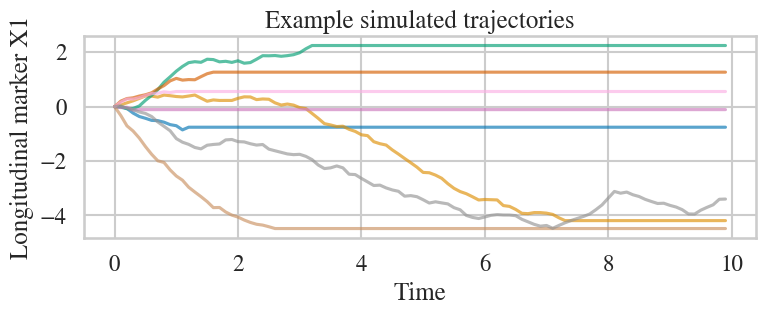

In [4]:
fig, ax = plt.subplots(figsize=(8, 3.5))
for i in range(min(8, len(paths))):
    ax.plot(sampling_times, paths[i, :, 1].cpu().numpy(), alpha=0.65)
ax.set(xlabel="Time", ylabel="Longitudinal marker X1", title="Example simulated trajectories")
plt.tight_layout()
plt.show()

## 2. Split the data and train CoxSig

We use a fixed random train/test split. For a publication-grade comparison, use the same split across models and repeat experiments over multiple seeds.

In [5]:
rng = np.random.default_rng(SEED)
indices = rng.permutation(len(paths))
n_train = int(0.8 * len(indices))
train_idx, test_idx = indices[:n_train], indices[n_train:]

def take_rows(x, idx):
    return None if x is None else x[idx]

paths_train, paths_test = paths[train_idx], paths[test_idx]
labels_train, labels_test = surv_labels[train_idx], surv_labels[test_idx]
static_train = take_rows(static_feature, train_idx)
static_test = take_rows(static_feature, test_idx)

coxsig = CoxSignature(sig_level=2, alphas=0.3, max_iter=200)
coxsig.train(paths_train, labels_train, static_train, plot_loss=False)
print("CoxSig training completed.")

CoxSig training completed.


## 3. Evaluate dynamic prediction

A *landmark time* is the time at which the prediction is made. An *evaluation horizon* specifies how far into the future predictive performance is assessed.

For consistency with the original experiments, landmark times are chosen using quantiles of **observed event times**. This is a tutorial convention, not a censoring-adjusted estimate of event-time quantiles.

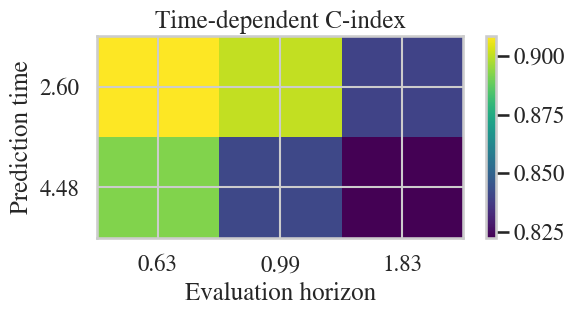

In [6]:
observed_events = surv_labels[event_indicators == 1, 0]
quantile_pred_times = np.array([0.5, 0.75])
eval_quantile_step = 0.05

pred_times = np.quantile(observed_events, quantile_pred_times)
eval_times = np.array([
    np.max(
        np.quantile(
            observed_events,
            np.minimum(quantile_pred_times + (k + 1) * eval_quantile_step, 1.0),
        ) - pred_times
    )
    for k in range(3)
])

c_index = coxsig.score(
    paths_test, labels_test, pred_times, eval_times,
    "c_index", static_feat=static_test,
)

fig, ax = plt.subplots(figsize=(6, 3.5))
im = ax.imshow(np.asarray(c_index), aspect="auto", cmap="viridis")
ax.set_xticks(range(len(eval_times)), [f"{t:.2f}" for t in eval_times])
ax.set_yticks(range(len(pred_times)), [f"{t:.2f}" for t in pred_times])
ax.set(xlabel="Evaluation horizon", ylabel="Prediction time", title="Time-dependent C-index")
fig.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()

## 4. Explain predictions with DynSurvX

`explainer` wraps the trained CoxSig model and a reference population. `survshap_longi` explains one individual's prediction at a selected landmark time.

The original notebook filters to individuals whose observed follow-up extends beyond the landmark time plus a small margin. We retain that convention, but **this selection is for demonstration only**: selecting subjects using future follow-up can introduce selection bias in population-level interpretation.

The current public call uses `prediction_type`, `n_split`, `intercept`, and `reg`. We do not pass `delta_1` or `delta_2` as extra keywords because the original tutorial did not expose them in this function's call signature.

In [7]:
pred_time = float(pred_times[0])
dt = float(sampling_times[1] - sampling_times[0])

eligible = surv_times > pred_time + 10 * dt
eligible_idx = np.flatnonzero(eligible)

sel_paths = paths[eligible_idx]
sel_labels = surv_labels[eligible_idx]
sel_static = take_rows(static_feature, eligible_idx)

if len(sel_paths) == 0:
    raise RuntimeError("No eligible individuals. Reduce the landmark time or follow-up margin.")

model_explainer = explainer(
    coxsig, "coxsig", sel_paths, sel_labels, sel_static
)

n_explain = min(N_EXPLAIN, len(sel_paths))
shap_results = []

for i in range(n_explain):
    result = survshap_longi(
        model_explainer,
        i,
        sel_paths[i],
        None if sel_static is None else sel_static[i],
        pred_time=np.array([pred_time]),
        prediction_type=PREDICTION_TYPE,
        seed=SEED + i,
        n_split=N_SPLIT,
        intercept=False,
        reg=SHAP_REG,
    )
    shap_results.append(result)

print(f"Explained {len(shap_results)} individuals at landmark time {pred_time:.2f}.")

100%|██████████| 1/1 [00:01<00:00,  1.77s/it]

Explained 5 individuals at landmark time 2.60.


## 5. Visualize temporal feature attribution

In the original implementation, each result starts with two arrays: the attribution numerator and a normalization denominator. Their elementwise ratio is used as the reported normalized importance.

We preserve this transformation and avoid dividing by zero. Before interpreting an attribution as positive or negative evidence, consult the implementation's normalization convention.

In [8]:
normalized = []

for result in shap_results:
    numerator = np.asarray(result[0], dtype=float)
    denominator = np.asarray(result[1], dtype=float)

    importance = np.divide(
        numerator,
        denominator,
        out=np.full_like(numerator, np.nan, dtype=float),
        where=denominator != 0,
    )
    normalized.append(importance)

importance_stack = np.stack(normalized, axis=0)
mean_importance = np.nanmean(importance_stack, axis=0)

print("Individual importance shape:", importance_stack.shape)
print("Average importance shape:", mean_importance.shape)

Individual importance shape: (5, 8, 100)
Average importance shape: (8, 100)


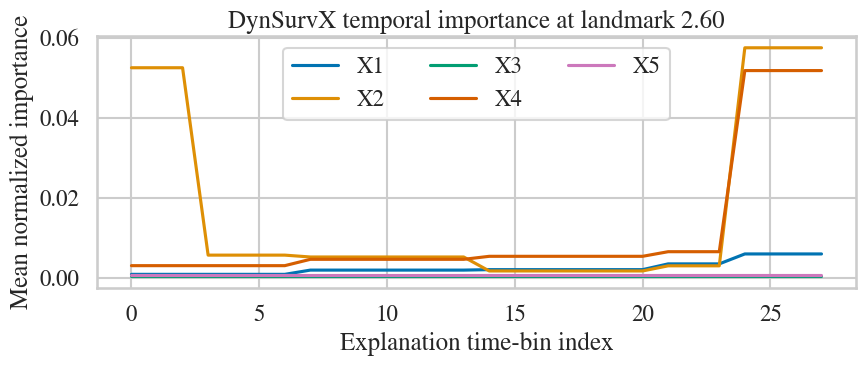

In [9]:
n_features, n_bins = mean_importance.shape
feature_labels = (
    [f"X{i + 1}" for i in range(n_longi_feats)]
    + [f"W{i + 1}" for i in range(n_features - n_longi_feats)]
)

# The explainer's output bins may differ from the original sampling grid.
# Plot bin indices rather than claiming an exact time mapping.
fig, ax = plt.subplots(figsize=(9, 4))
for j in range(min(n_longi_feats, n_features)):
    ax.plot(np.arange(n_bins), mean_importance[j], label=feature_labels[j])

ax.set(
    xlabel="Explanation time-bin index",
    ylabel="Mean normalized importance",
    title=f"DynSurvX temporal importance at landmark {pred_time:.2f}",
)
ax.legend(ncol=3)
plt.tight_layout()
plt.show()

## 6. Aggregate importance by feature

Summing the normalized time-bin scores gives a simple feature-level summary. This is an **aggregation convention**; its interpretation depends on whether the normalized scores are signed and on how the method handles interval lengths.

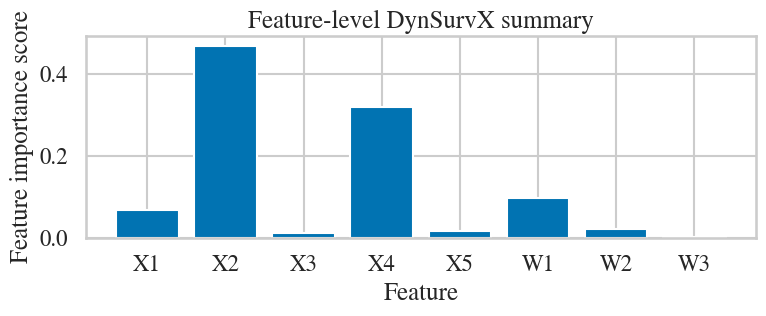

In [11]:
feature_importance = np.nansum(mean_importance, axis=1)

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(feature_labels, feature_importance)
ax.set(
    xlabel="Feature",
    ylabel="Feature importance score",
    title="Feature-level DynSurvX summary",
)
plt.tight_layout()
plt.show()

## 7. Next steps

- Change `PREDICTION_TYPE` to `"med-survival"` to explain median residual survival time.
- Increase `N_EXPLAIN` for more stable population-level summaries.
- Repeat explanations at multiple landmark times and compare how the temporal attribution changes.
- For full paper reproduction, use the repository's experiment scripts and dataset/model-specific JSON configuration.

**Interpretation caveats:** CoxSig coefficient magnitudes are not interchangeable with Shapley importance; normalization can affect cross-feature comparisons; and the tutorial's follow-up-based eligibility rule should not be treated as a prospective sampling design.